# LAB 01 WEEK 05 - EDA Univariate Analysis 

Amazon UK Product Insights Report

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Define folder path here if needed, mind windows \ notation and str escape syntax
csv_path = 'amazon_uk_products.csv'

# Open csv file
df = pd.read_csv(csv_path)

# Examine Product Categories
df.head(50) # Get first 50 entries - all Hifi Speakers

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


### Part 1: Market Composition & Category Popularity

Question: What are the most popular product categories on Amazon UK, and what are their listing frequencies?


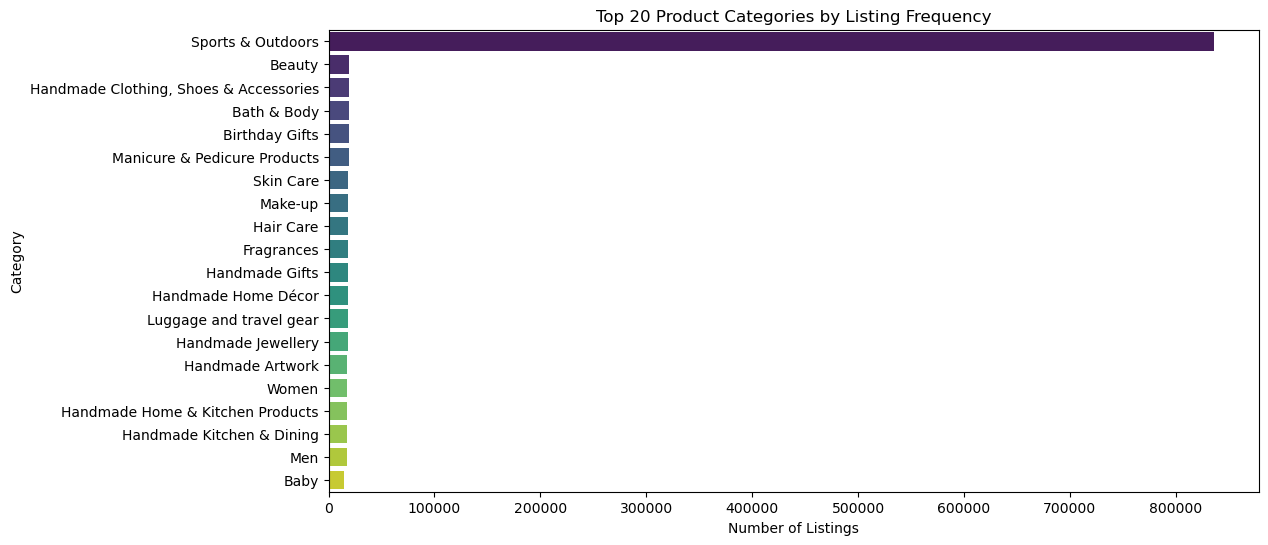

In [9]:
# Generate Frequency Tables & Top Categories

# Frequency Table for Top 5
category_counts = df['category'].value_counts()

# Dataviz 
# Bar Chart for Top 20 Categories (or fewer if it gets too cluttered)
plt.figure(figsize=(12, 6))
sns.barplot(
    x=category_counts.head(20).values, 
    y=category_counts.head(20).index, 
    hue=category_counts.head(20).index,
    palette='viridis',
    legend=False
)
plt.title('Top 20 Product Categories by Listing Frequency')
plt.xlabel('Number of Listings')
plt.ylabel('Category')
plt.show()


--- Top 5 Most Listed Categories ---
category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64


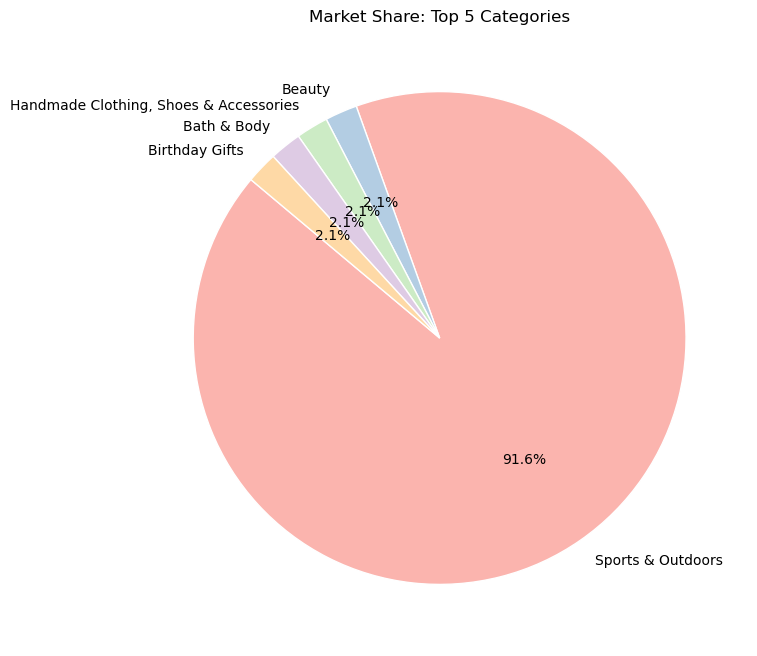

In [ ]:
# Dataviz for Top 5 Categories 
top_5 = category_counts.head(5)

# print("--- Top 5 Most Listed Categories ---")
# print(top_5)

# Pie Chart Top5
colors = sns.color_palette('Pastel1')
plt.figure(figsize=(8, 8))
plt.pie(top_5.values, labels=top_5.index, autopct='%1.1f%%', startangle=140, colors=colors, wedgeprops={'edgecolor': 'white'}) 
plt.title('Market Share: Top 5 Categories')
plt.show()

### Top Categories Excluding "Sports & Outdoors"

The "Sports & Outdoors" category alone comprises 91% of products. For a more fine grained visualization of the general catalog of Amazon products, it makes more sense to exclude the outlier and look at e.g., the top sales categories 2 to 11, excluding Sports. 

As these sums just represents the number of items *listed* on Amazon UK, this view does not allow further insights into the popularity and competition of products across categories. 


--- Top 10 Categories (Excluding Sports & Outdoors) ---
category
Beauty                                    19312
Handmade Clothing, Shoes & Accessories    19229
Bath & Body                               19092
Birthday Gifts                            18978
Manicure & Pedicure Products              18940
Skin Care                                 18769
Make-up                                   18756
Hair Care                                 18735
Fragrances                                18564
Handmade Gifts                            18295
Name: count, dtype: int64


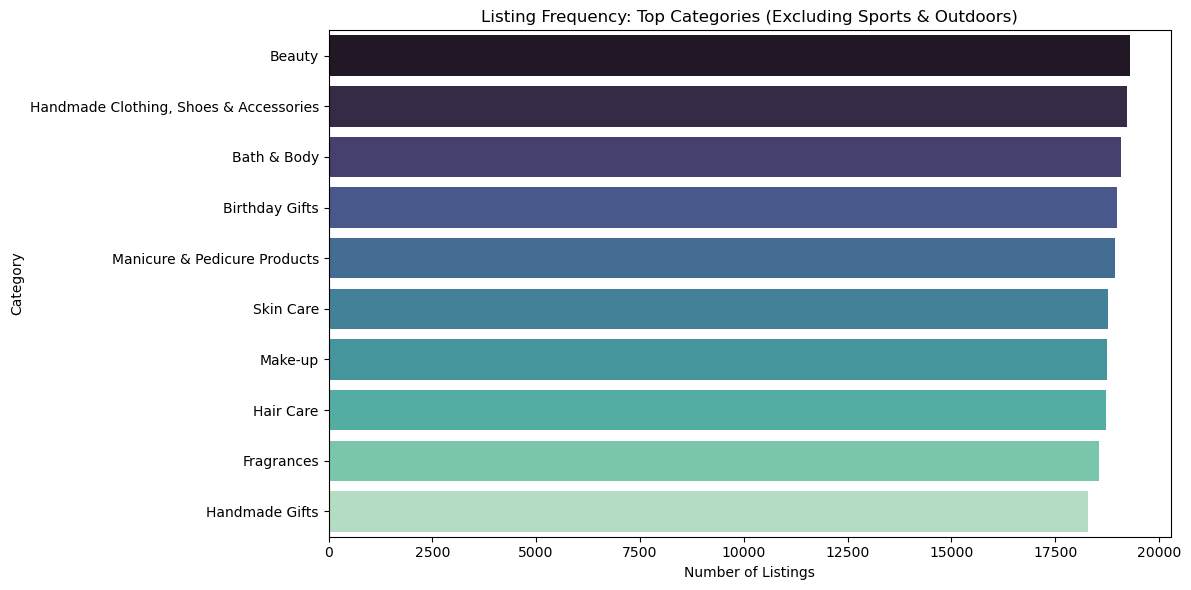

In [ ]:
# Exclude top category "Sports & Outdoors" from dataviz

# Slice from index 1 to 11
top_2_to_11 = category_counts.iloc[1:11]

print("\n--- Top 10 Categories (Excluding Sports & Outdoors) ---")
print(top_2_to_11)

# Bar Chart 
plt.figure(figsize=(12, 6))
sns.barplot(
    x=top_2_to_11.values, 
    y=top_2_to_11.index, 
    hue=top_2_to_11.index, 
    palette='mako', 
    legend=False
)

plt.title('Listing Frequency: Top Categories (Excluding Sports & Outdoors)')
plt.xlabel('Number of Listings')
plt.ylabel('Category')
plt.tight_layout() 
plt.show()

### Remarks on Top Categories Analysis 

The dominance of products in the "Sports & Outdoors" category is likely a strong bias of the dataset itself, and could have several reasons. The simplest explanation is that the data stems from a very specialized source like a sports tickets or clothing retailer, from a filtered or very niche seller report, or that it has simply been mislabeled. 

However, in the Amazon clothing segment, sports items are also highly regulated, possibly counterfeit prone, and characterized by high-volume turnover and stiff competition in general. Sports-related items certainly belong to the top sellers in the UK consumer market, and the outlier here could be connected to seasonal peaks (like the Olympics or football games) - but the 91% are obviously inflated and do not represent the real proportion of Amazon sales or revenue in that area. 

If you exclude the Sports outlier, the following top categories are much more likely and typical of Amazon market shares and top sellers by actual sales and revenue. Here we see more representative rubrics like Home & Garden, Beauty & Cosmetics, Clothing & Accessories - all with a very similar numbers of products, around 18-19.000 items. 

As all other categories have fewer than 20K items, this gives a more realistic and appropriate range of items listed on the platform. There is a limit to the variety of products people can make real selections from, and the total numbers do indicate that the competition for new products is incredibly harsh and the individual category markets are already saturated, making it hard for newcomers and novelty products.  

### Part 2: Delving Into Product Pricing

Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

In [ ]:
# Part 2: Product Pricing -- Measures of Centrality & Dispersion

# Cast price to numeric just in case
df['price'] = pd.to_numeric(df['price'], errors='coerce')

# Measures of Centrality
mean_p = df['price'].mean()
med_p = df['price'].median()
mode_p = df['price'].mode()[0] # Take first mode if there are several 

print(f"Average Price (Mean): £{mean_p:.2f}")
print(f"Middle Price (Median): £{med_p:.2f}")
print(f"Most Common (Mode): £{mode_p:.2f}")

Average Price (Mean): £89.24
Middle Price (Median): £19.09
Most Common (Mode): £9.99


In [14]:
# Measures of Dispersion
std_p = df['price'].std()
var_p = df['price'].var()
iqr_p = df['price'].quantile(0.75) - df['price'].quantile(0.25)

print(f"Standard Deviation: {std_p:.2f}")
print(f"Variance: {var_p:.2f}")
print(f"Interquartile Range: {iqr_p:.2f}")

Standard Deviation: 345.61
Variance: 119445.49
Interquartile Range: 36.00


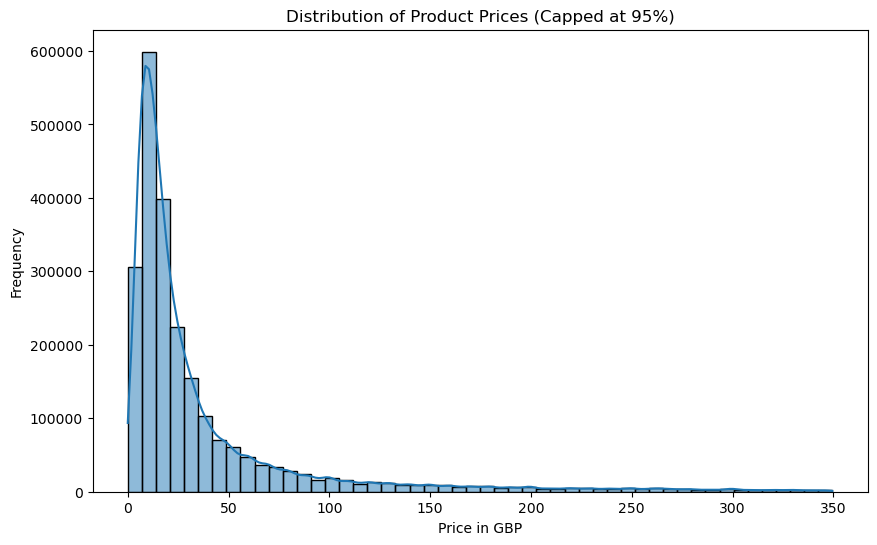

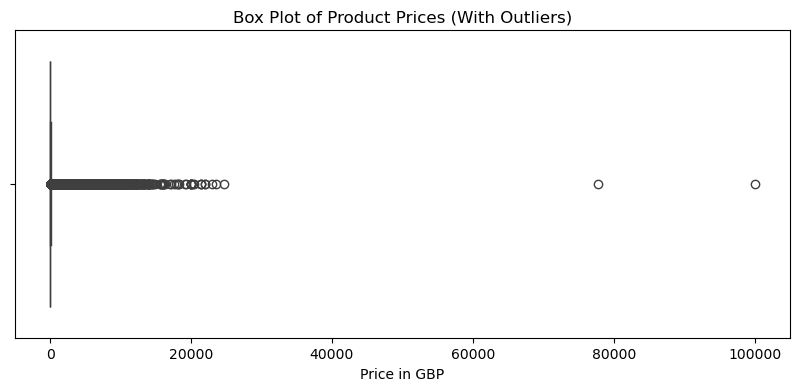

In [15]:
# Visualizations of Price Range

# Limit x axis to avoid showing extreme outlier prices
price_95th_percentile = df['price'].quantile(0.95)

# Histogram
plt.figure(figsize=(10, 6))
sns.histplot(df[df['price'] <= price_95th_percentile]['price'], bins=50, kde=True)
plt.title('Distribution of Product Prices (Capped at 95%)')
plt.xlabel('Price in GBP')
plt.ylabel('Frequency')
plt.show()


# Box Plot
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['price'])
plt.title('Box Plot of Product Prices (With Outliers)')
plt.xlabel('Price in GBP')
plt.show()


### Remarks on Price Ranges 

There is a right skew of the data due to the notably large difference between the mean product price of 89.24 GBP and the median price of 19.09 GBP. This is quite typical for a large retailer like Amazon, and indicative of the "Long Tail": most products are moderately priced and affordable at under 20 GBP, but the much rarer expensive orders in the upper 1000s lift the mean price up to almost 90 pounds. 

The most common price of 9.99 is to be expected, due to psychological pricing the 9s appear far more frequently overall than the subsequent 10s. This can be visualized by omitting the Long Tail (the top 5 percent of prices). To display all data including the top tier, scaling to a log view can summarize the cheaper, mid-range and luxury items in one chart.  


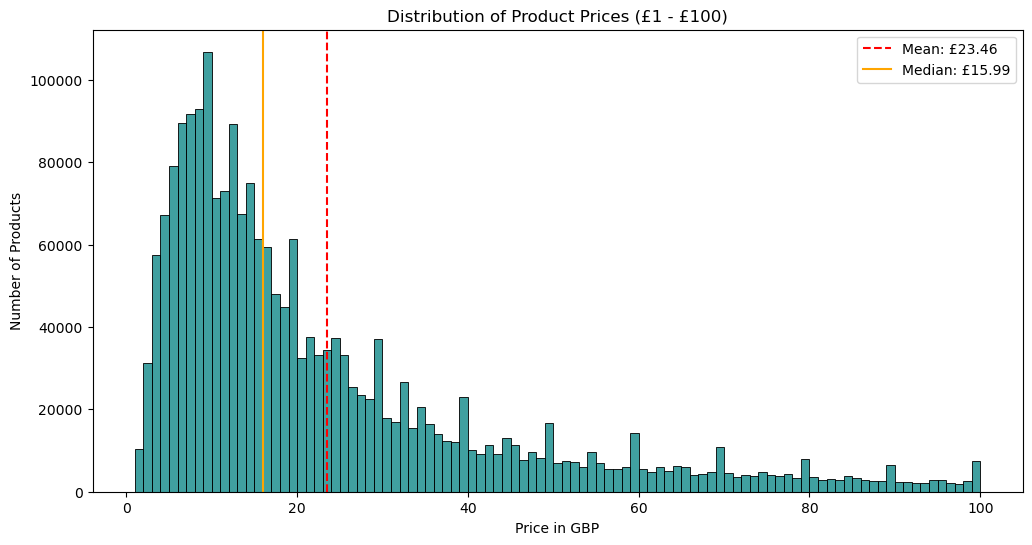

In [16]:
# Redo Price Range visualization to omit Long Tail and show 99p price points 

df_filtered = df[(df['price'] >= 1) & (df['price'] <= 100)]

plt.figure(figsize=(12, 6))

# Plotting with a 1 pound width to see .99p peaks
sns.histplot(data=df_filtered, x='price', binwidth=1, kde=False, color='teal')

# Add lines for the Mean and Median 
plt.axvline(df_filtered['price'].mean(), color='red', linestyle='--', label=f"Mean: £{df_filtered['price'].mean():.2f}")
plt.axvline(df_filtered['price'].median(), color='orange', linestyle='-', label=f"Median: £{df_filtered['price'].median():.2f}")

plt.title('Distribution of Product Prices (£1 - £100)')
plt.xlabel('Price in GBP')
plt.ylabel('Number of Products')
plt.legend()
plt.show()

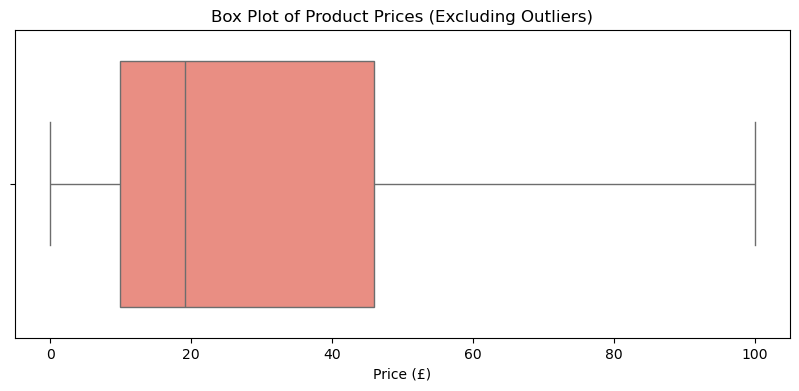

In [ ]:
# Box Plot Excluding Outliers
plt.figure(figsize=(10, 4))

# Remove the fliers (outlier dots)
sns.boxplot(x=df['price'], showfliers=False, color='salmon') # Use contrasting colours for box and hist plots

plt.title('Box Plot of Product Prices (Excluding Outliers)')
plt.xlabel('Price (£)')
plt.show() 

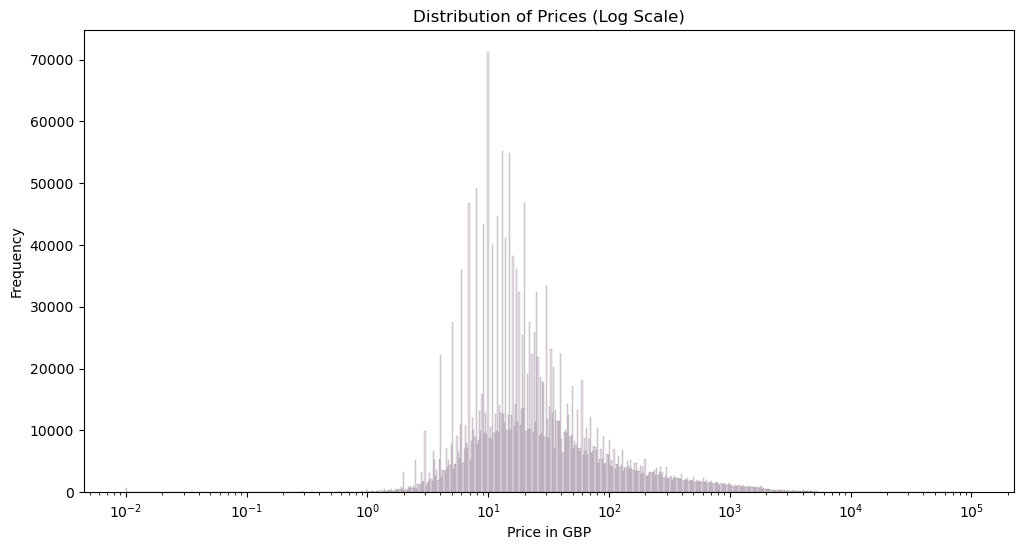

In [ ]:
# Price Distribution Using Log Scale  
plt.figure(figsize=(12, 6))

# Set log_scale=True to transform x axis
sns.histplot(data=df, x='price', log_scale=True, kde=True, color='thistle')

plt.title('Distribution of Prices (Log Scale)')
plt.xlabel('Price in GBP')
plt.ylabel('Frequency')
plt.show()

### Remarks on Price Dispersion

Omitting the Long Tail of products priced at over 350K and plotting to a log scale gives a more accurate picture of price ranges and dispersion of the data. The mean (23.46) and median (15.99) price in pounds have moved closer together and are more representative of actual consumer behaviour. The visible peaks at 9.99 (the mode or most common price), 19.99 pounds etc. demonstrate the common use of price "anchors" as a marketing ploy.   

By making these peaks and the overall price tiers more clearly visible, we can show that the most important area of business by far are affordable, everyday products. Amazon's focus on standard consumer goods like fashion, beauty, cosmetics, home appliances and other staple items is the large majority of their business. In the log-scale plots, you can see that the dispersion of cheap, mid and expensive products is quite well-balanced and follows a close to normal distribution pattern.

The Standard Deviation of 345.61 of all prices (Variance: 119445.49) is very high, which tells us that there is no such thing as a standard, average price for Amazon products. Again, this is expected for a global player like Amazon, and shows that the platform performs differently in different segments but manages to maintain a "big tent" of more niche products like a true generalist marketplace.

All price bins skew to the 9s, but the differences between the prices in any given rubric across all categories are huge. An IQR of 36 pounds tells us that half of sales are clustered in this very narrow range of prices, so most sold items will be in that relatively affordable price range.


### Part 3: Unpacking Product Ratings 

Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

In [23]:
# Analysing the "Stars" Ratings System

rating_col = 'stars' 

# 1. Measures of Centrality
rating_mean = df[rating_col].mean()
rating_median = df[rating_col].median()
rating_mode = df[rating_col].mode()[0] 

print(f"Ratings Mean: {rating_mean:.2f}")
print(f"Ratings Median: {rating_median:.2f}")
print(f"Ratings Mode: {rating_mode:.2f}")

# 2. Measures of Dispersion
rating_variance = df[rating_col].var()
rating_std = df[rating_col].std()
rating_iqr = df[rating_col].quantile(0.75) - df[rating_col].quantile(0.25)

print(f"Ratings Variance: {rating_variance:.2f}")
print(f"Ratings Standard Deviation: {rating_std:.2f}")
print(f"Ratings IQR: {rating_iqr:.2f}")

# 3. Shape of the Distribution
rating_skew = df[rating_col].skew()
rating_kurtosis = df[rating_col].kurtosis()

print(f"Ratings Skew: {rating_skew:.2f}")
print(f"Ratings Kurtosis: {rating_kurtosis:.2f}")

Ratings Mean: 2.15
Ratings Median: 0.00
Ratings Mode: 0.00
Ratings Variance: 4.82
Ratings Standard Deviation: 2.19
Ratings IQR: 4.40
Ratings Skew: 0.08
Ratings Kurtosis: -1.93


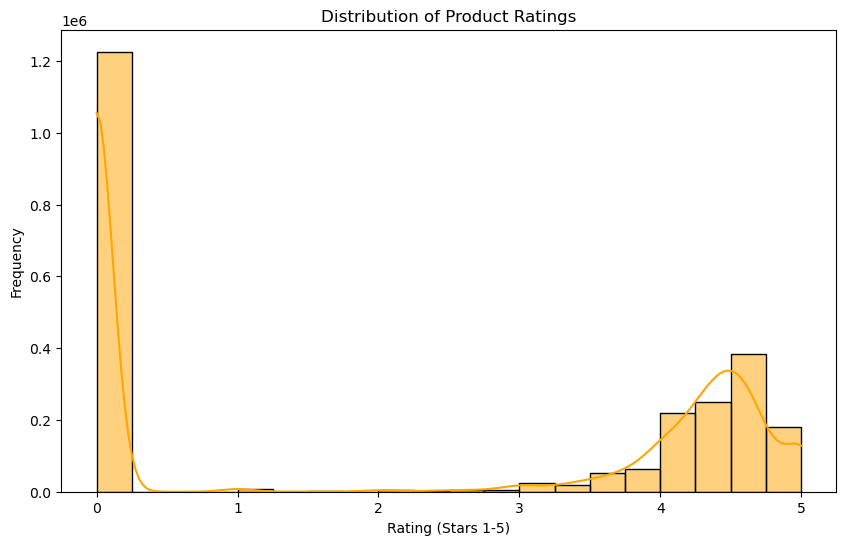

In [24]:
# 4. Visualization
plt.figure(figsize=(10, 6))
sns.histplot(df[rating_col].dropna(), bins=20, kde=True, color='orange')
plt.title('Distribution of Product Ratings')
plt.xlabel('Rating (Stars 1-5)')
plt.ylabel('Frequency')
plt.show()

Percentage of products with NO rating (0 Stars): 50.16%


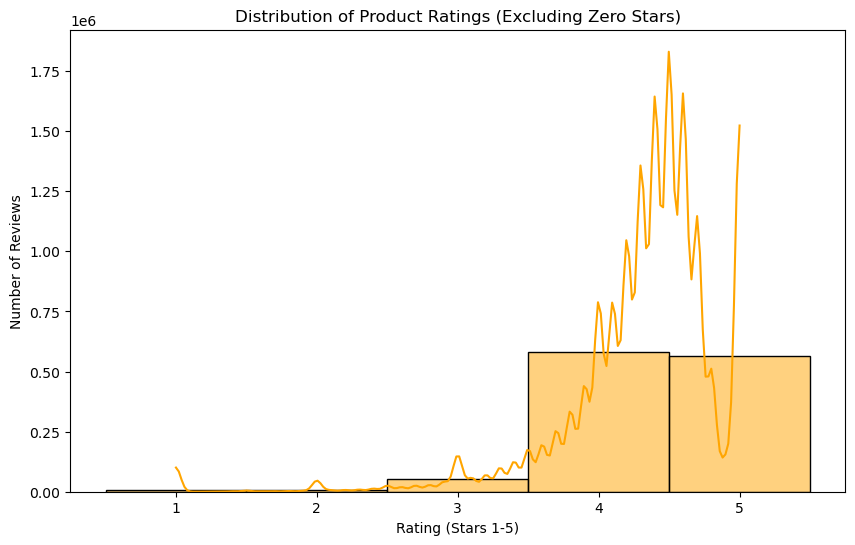

In [25]:
# Redo to exclude the Zero star ratings (products with no ratings)
total_products = len(df)

zero_ratings_count = (df[rating_col] == 0).sum()
percentage_zero = (zero_ratings_count / total_products) * 100

print(f"Percentage of products with NO rating (0 Stars): {percentage_zero:.2f}%")

# New plot for 1-5 stars only

# Filter to only include ratings between 1 and 5
plot_data = df[df[rating_col] > 0].dropna()
plt.figure(figsize=(10, 6))
# Center bars on discrete values 1-5
sns.histplot(data=plot_data, x=rating_col, bins=5, kde=True, color='orange', discrete=True)

plt.title('Distribution of Product Ratings (Excluding Zero Stars)')
plt.xlabel('Rating (Stars 1-5)')
plt.ylabel('Number of Reviews')
plt.xticks([1, 2, 3, 4, 5]) # Make labels the exact star counts
plt.show()

In [26]:
# Redo Statistical Measures 

# Create a filtered version
df_rated = df[df[rating_col] > 0].dropna(subset=[rating_col]).copy()

print(f"Original Dataset Size: {len(df)}")
print(f"Rated Dataset Size:    {len(df_rated)}")

# 1. Measures of Centrality
rating_mean = df_rated[rating_col].mean()
rating_median = df_rated[rating_col].median()
rating_mode = df_rated[rating_col].mode()[0] 

# 2. Measures of Dispersion
rating_variance = df_rated[rating_col].var() # Remember: This is Sample Variance (n-1)
rating_std = df_rated[rating_col].std()
rating_iqr = df_rated[rating_col].quantile(0.75) - df_rated[rating_col].quantile(0.25)

# 3. Shape of the Distribution
rating_skew = df_rated[rating_col].skew()
rating_kurtosis = df_rated[rating_col].kurtosis()

# Print entire updated report for 
print("--- RATINGS ANALYSIS (1-5 STARS ONLY) ---")
print(f"Centrality: Mean={rating_mean:.2f}, Median={rating_median:.2f}, Mode={rating_mode:.2f}")
print(f"Dispersion: Std Dev={rating_std:.2f}, Var={rating_variance:.2f}, IQR={rating_iqr:.2f}")
print(f"Shape:      Skew={rating_skew:.2f}, Kurtosis={rating_kurtosis:.2f}")

Original Dataset Size: 2443651
Rated Dataset Size:    1218010
--- RATINGS ANALYSIS (1-5 STARS ONLY) ---
Centrality: Mean=4.32, Median=4.40, Mode=4.50
Dispersion: Std Dev=0.56, Var=0.31, IQR=0.50
Shape:      Skew=-2.38, Kurtosis=9.78


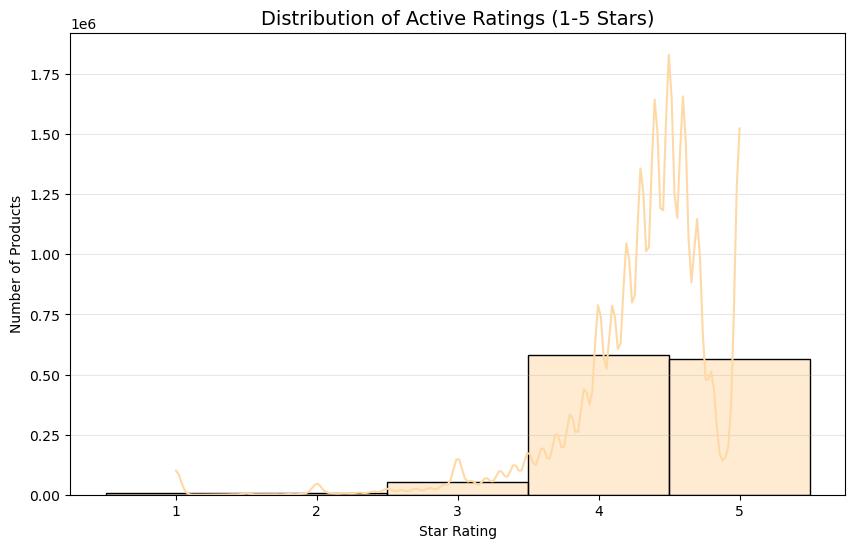

In [27]:
# Plot new ratings chart
plt.figure(figsize=(10, 6))
soft_orange = sns.color_palette('Pastel1')[4] 
sns.histplot(data=df_rated, x=rating_col, discrete=True, kde=True, color=soft_orange) # Use 'discrete=True' to align bars with stars 1 to 5

plt.title('Distribution of Active Ratings (1-5 Stars)', fontsize=14)
plt.xlabel('Star Rating')
plt.ylabel('Number of Products')
plt.xticks([1, 2, 3, 4, 5]) # Force x-axis to show only the star levels
plt.grid(axis='y', alpha=0.3)

plt.show()


# Remarks on Ratings Data (Stars 1 to 5)

Most Amazon ratings follow a "J" form (heavily skewed around 4 and 5 stars). With a mean of 4.32 and a strong negative skew of -2.38, products with 3.5 stars for example are likely *perceived* as rated average to good, but in reality are not performing well at all relative to the market average -- thus they represent a rating on the lower end of consumer satisfaction.  

The clear negative skew confirms a kind of selection bias, in the sense that Amazon UK customers are by far more likely to leave a high rating than a low one -- implying that many unsatisfied customers are contributing to the half of 0 Stars products ratings, and rather leave no rating at all than a low one around 1-2 stars. This also means that a 4-star Amazon review is not in the same class as say, a 4-star hotel -- a rating around 4.3-4.4 star ratings being the absolute average baseline at least for the UK market.

Remembering the high percentage of products with no ratings at all (zero stars) calculated above, this can also imply a certain risk for newcomers in terms of inventory. Breaking into categories like Sports, Clothing or even Beauty products with almost 20k items, brings a significant inventory risk for new sellers -- with half of the listed products being "cold starters" (newly listed products that don't have any ratings yet, or even remain unnoticed at the bottom of the product listings forever) that remain in inventory indefinitely. Again an indicator of the tough competition of Amazon sellers: Products with no "social proof" whatsoever will remain unnoticed and unrated for random lengths of time, making inventory and order management challenging especially for newcomers to competitive categories. 

The high averages and modes in general tend to the full 5 stars. This tells us that the most common customer's experience is actually almost perfect (or that only users only leave reviews when fully satisfied) -- again pointing to a brutal survivorship bias for individual sellers. Half of all products will almost certainly remain in the ignored and underrated long tail of over-abundant products for a long time.  

This has implications for market (entry) strategies: Newcomers should look at underserved categories that have fewer products, but high average ratings. What are the minimum average customer ratings needed to break in, and remain visible and competitive in the Top Categories? These are higher than probably many would think, and the exclusion factor for the risk of products remaining unnoticed in the backend of the listings and therefore without significant ratings, is a brutal 50 percent. 